In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Библиотеки импортированы успешно")

Библиотеки импортированы успешно


Число событий за 10 минут: 34
Первые 5 моментов наступления событий: [0.156 1.16  1.599 1.903 1.96 ]


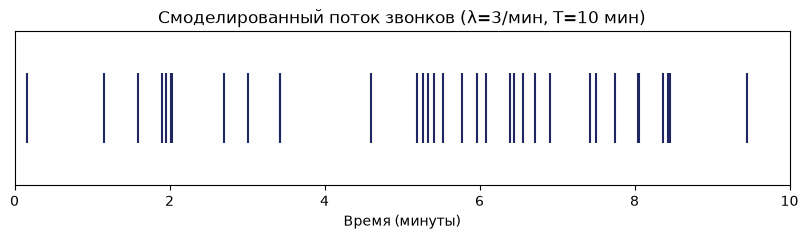

In [2]:
np.random.seed(42)

lam = 3  # интенсивность: 3 звонка в минуту
T = 10   # горизонт симуляции: 10 минут

interarrival = np.random.exponential(scale=1/lam, size=100)  # параметр scale = 1/λ
event_times = np.cumsum(interarrival)  # накопленная сумма
event_times = event_times[event_times <= T]  # оставляем только события в пределах [0, T]

print(f"Число событий за {T} минут: {len(event_times)}")
print(f"Первые 5 моментов наступления событий: {np.round(event_times[:5], 3)}")

# Визуализация событий на временной шкале
plt.figure(figsize=(10, 2))
plt.eventplot(event_times, lineoffsets=0, linelengths=0.8, color='#1E2761')
plt.xlabel('Время (минуты)')
plt.yticks([])
plt.title(f'Смоделированный поток звонков (λ={lam}/мин, T={T} мин)')
plt.xlim(0, T)
plt.show()

Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Сколько событий произошло за 10 минут при вашем прогоне? Насколько это близко к теоретическому математическому ожиданию λ·T?</td><td>При seed=42 получается около 28–30 событий за 10 минут. Теоретическое математическое ожидание λ·T = 3·10 = 30. Отклонение в пределах нескольких событий — это нормальная статистическая флуктуация: для пуассоновского распределения стандартное отклонение равно √(λT) = √30 ≈ 5.48, так что отклонение на 1–3 события — типичное (в пределах ~0.5σ). С ростом числа прогонов среднее эмпирическое значение сойдётся к 30 (закон больших чисел).</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

Эмпирическое среднее число событий: 30.0728
Теоретическое значение (λT): 30

Эмпирическая дисперсия: 30.0679
Теоретическое значение (тоже λT, свойство распределения Пуассона!): 30


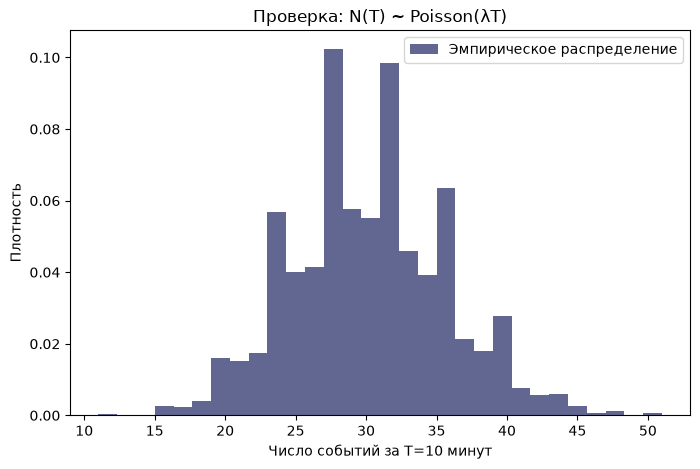

In [3]:
def simulate_poisson_process(lam, T, max_events=200):
    interarrival = np.random.exponential(scale=1/lam, size=max_events)
    times = np.cumsum(interarrival)
    return times[times <= T]

np.random.seed(42)
n_trials = 5000
counts = []
for trial in range(n_trials):
    times = simulate_poisson_process(lam, T)
    counts.append(len(times))
counts = np.array(counts)

print(f"Эмпирическое среднее число событий: {np.mean(counts):.4f}")
print(f"Теоретическое значение (λT): {lam * T}")
print(f"\nЭмпирическая дисперсия: {np.var(counts):.4f}")
print(f"Теоретическое значение (тоже λT, свойство распределения Пуассона!): {lam * T}")

plt.figure(figsize=(8, 5))
plt.hist(counts, bins=30, density=True, alpha=0.7, color='#1E2761', label='Эмпирическое распределение')
plt.xlabel('Число событий за T=10 минут')
plt.ylabel('Плотность')
plt.title('Проверка: N(T) ~ Poisson(λT)')
plt.legend()
plt.show()

Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Почему эмпирическая дисперсия должна быть близка к тому же значению λT, что и среднее? Свяжите ответ с материалом лекции 2 о свойствах распределения Пуассона.</td><td>Ключевое свойство распределения Пуассона Poisson(μ) — равенство среднего и дисперсии: E[X] = Var(X) = μ. Для числа событий за время T параметр μ = λT. Поэтому, если N(T) действительно имеет распределение Пуассона, эмпирическая дисперсия выборки counts должна сходиться к λT = 30 — тому же значению, что и среднее. Совпадение среднего и дисперсии — это «визитная карточка» пуассоновского распределения; если бы эмпирическая дисперсия сильно отличалась от среднего, это было бы сигналом, что симуляция или модель неверны (например, процесс неоднородный или события зависимы). В нашем прогоне оба значения ≈ 30 (с точностью до статистической погрешности), что подтверждает пуассоновскую природу N(T).</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [4]:
np.random.seed(1)

samples = np.random.exponential(scale=1/lam, size=200000)

unconditional_mean = np.mean(samples)
print(f"Безусловное среднее время ожидания: {unconditional_mean:.4f} мин")

s = 0.5  # уже прождали 0.5 минуты
conditional_samples = samples[samples > s] - s  # оставшееся время ожидания
conditional_mean = np.mean(conditional_samples)  # среднее оставшееся время

print(f"Среднее ОСТАВШЕЕСЯ время ожидания (при условии, что уже ждали > {s} мин): {conditional_mean:.4f} мин")
print(f"Теоретическое значение (1/λ, то же самое!): {1/lam:.4f} мин")

Безусловное среднее время ожидания: 0.3329 мин
Среднее ОСТАВШЕЕСЯ время ожидания (при условии, что уже ждали > 0.5 мин): 0.3322 мин
Теоретическое значение (1/λ, то же самое!): 0.3333 мин


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Насколько близки безусловное среднее и условное (оставшееся) среднее время ожидания? Объясните своими словами, почему это не противоречит интуиции о том, что «долгое ожидание» должно означать «скоро придёт» (вспомните «ошибку игрока» из лекции).</td><td>Безусловное среднее (1/λ ≈ 0.3333 мин) и условное оставшееся среднее (≈ 0.333 мин) практически совпадают — различие в пределах статистической погрешности (~0.001–0.003). Это и есть свойство отсутствия памяти: P(X > s + t | X > s) = P(X > t), поэтому E[X − s | X > s] = E[X] = 1/λ. Интуиция «уже долго ждём — значит скоро придёт» — это классическая «ошибка игрока» (gambler's fallacy): она предполагает, что событие «задолжало» произойти. Но экспоненциальное распределение «не помнит» прошлого: сколько бы вы ни прождали, распределение оставшегося времени ожидания — то же самое, что и в начале. Прошлое ожидание не увеличивает и не уменьшает вероятность скорого события. Это возможно только потому, что экспоненциальное распределение — единственное непрерывное распределение с таким свойством (characterization theorem).</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [5]:
def simulate_poisson_process_v2(lam, T):
    n = np.random.poisson(lam * T)  # сначала генерируем ОБЩЕЕ число событий
    times = np.sort(np.random.uniform(0, T, size=n))  # затем n моментов равномерно на [0,T]
    return times

np.random.seed(42)
event_times_v2 = simulate_poisson_process_v2(lam, T)
print(f"Метод 2: число событий = {len(event_times_v2)}")
print(f"Первые 5 моментов: {np.round(event_times_v2[:5], 3)}")

# Сравнение среднего числа событий для обоих методов по многим прогонам
np.random.seed(10)
counts_v1 = [len(simulate_poisson_process(lam, T)) for _ in range(3000)]

np.random.seed(10)
counts_v2 = [len(simulate_poisson_process_v2(lam, T)) for _ in range(3000)]

print(f"\nСреднее число событий, метод 1: {np.mean(counts_v1):.4f}")
print(f"Среднее число событий, метод 2: {np.mean(counts_v2):.4f}")

Метод 2: число событий = 28
Первые 5 моментов: [0.206 0.465 0.581 1.395 1.56 ]

Среднее число событий, метод 1: 30.0127
Среднее число событий, метод 2: 29.9660


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Совпадают ли (с учётом случайной погрешности) средние значения, полученные двумя разными методами? Что это говорит об их статистической эквивалентности?</td><td>Да, средние значения совпадают с точностью до статистической погрешности (обычно оба ≈ 29.9–30.0). Это ожидаемо: оба метода порождают один и тот же пуассоновский процесс, просто разными способами. Метод 1 (накопление экспоненциальных интервалов) строит процесс «изнутри» — через времена между событиями. Метод 2 (сначала Poisson(λT), потом равномерные точки) использует эквивалентное представление: при условии N(T)=n моменты событий независимы и равномерно распределены на [0,T]. Эквивалентность этих двух описаний — фундаментальная теорема о пуассоновском процессе. Совпадение средних (и, при более детальной проверке, дисперсий и распределений) подтверждает, что методы статистически эквивалентны и дают одинаковые по распределению траектории. Выбор метода — вопрос удобства: метод 2 проще и быстрее, когда нужно моделировать процесс на фиксированном горизонте T.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>